# EJERCICIOS

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import joblib
from sklearn.datasets import load_digits
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MultiLabelBinarizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve,confusion_matrix
from sklearn.svm import SVC 
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_curve, auc, accuracy_score
from scipy.stats import reciprocal
from sklearn.feature_extraction.text import TfidfVectorizer

## EJERCICIO 1

Vamos a trabajar con el un conjunto de datos sobre prestamos que tiene las siguientes columnas:

| Variable      	| Explicación                                                                                                             |
|-------------------|-------------------------------------------------------------------------------------------------------------------------|
| credit_policy	    | 1 si el cliente cumple con los criterios de suscripción de crédito; 0 en caso contrario.                                |
| purpose	        | El propósito del préstamo.                                                                                              |
| int_rate	        | La tasa de interés del préstamo (a los prestatarios más riesgosos se les asignan tasas más altas).                      |
| installment	    | Las cuotas mensuales del prestamo                                                                                       |
| log_annual_inc    | El logaritmo natural del ingreso anual declarado por el prestatario.                                                    |
| dti	            | La relación deuda-ingreso del prestatario (monto de deuda dividido por ingresos anuales).                               |
| fico	            | El puntaje de crédito FICO del prestatario.                                                                             |
| days_with_cr_line	| El número de días que el prestatario ha tenido una línea de crédito.                                                    |
| revol_bal	        | El saldo rotativo del prestatario (monto no pagado al final del ciclo de facturación de la tarjeta).                    |
| revol_util        | La tasa de utilización de la línea de crédito del prestatario (monto de crédito utilizado respecto al total disponible).|
| inq_last_6mths	| El número de consultas de los acreedores al prestatario en los últimos 6 meses.                                         |
| delinq_2yrs	    | El número de veces que el prestatario ha estado más de 30 días en mora en un pago en los últimos 2 años.                |
| pub_rec	        | El número de registros públicos despectivos del prestatario.                                                            |
| not_fully_paid    | 1 si el préstamo se pagó totalmente; 0 en caso contrario.                                                        |

El csv lo tienes disponible en Moodle

Este conjunto de datos consta de más de 9500 préstamos con información sobre los datos del préstamo y si el préstamo fue pagado en su totalidad o no. Estos datos fueron extraídos de LendingClub.com
Crea un clasificador para predecir si un prestamo va a ser pagado o no.

### RECOPILACIÓN Y PREPARACIÓN DE LOS DATOS

#### OBTENER LOS DATOS

In [2]:
loan_data = pd.read_csv("datos/loan_data.csv")

#### EXPLORAR LOS DATOS

Entre otras cosas: estadísticas, matriz de correlaciones y borrar columnas innecesarias.

(9578, 14)
<class 'pandas.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   str    
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), str(1)
memory usage: 1.0 MB
None


,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
count,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9.578000e+03,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000
mean,0.804970,0.122640,319.089413,10.932117,12.606679,710.846314,4560.767197,1.691396e+04,46.799236,1.577469,0.163708,0.062122,0.160054
std,0.396245,0.026847,207.071301,0.614813,6.883970,37.970537,2496.930377,3.375619e+04,29.014417,2.200245,0.546215,0.262126,0.366676
min,0.000000,0.060000,15.670000,7.547502,0.000000,612.000000,178.958333,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.103900,163.770000,10.558414,7.212500,682.000000,2820.000000,3.187000e+03,22.600000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.122100,268.950000,10.928884,12.665000,707.000000,4139.958333,8.596000e+03,46.300000,1.000000,0.000000,0.000000,0.000000
75%,1.000000,0.140700,432.762500,11.291293,17.950000,737.000000,5730.000000,1.824950e+04,70.900000,2.000000,0.000000,0.000000,0.000000
max,1.000000,0.216400,940.140000,14.528354,29.960000,827.000000,17639.958330,1.207359e+06,119.000000,33.000000,13.000000,5.000000,1.000000


,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
credit.policy,1.000000,-0.294089,0.058770,0.034906,-0.090901,0.348319,0.099026,-0.187518,-0.104095,-0.535511,-0.076318,-0.054243,-0.158119
int.rate,-0.294089,1.000000,0.276140,0.056383,0.220006,-0.714821,-0.124022,0.092527,0.464837,0.202780,0.156079,0.098162,0.159552
installment,0.058770,0.276140,1.000000,0.448102,0.050202,0.086039,0.183297,0.233625,0.081356,-0.010419,-0.004368,-0.032760,0.049955
log.annual.inc,0.034906,0.056383,0.448102,1.000000,-0.054065,0.114576,0.336896,0.372140,0.054881,0.029171,0.029203,0.016506,-0.033439
dti,-0.090901,0.220006,0.050202,-0.054065,1.000000,-0.241191,0.060101,0.188748,0.337109,0.029189,-0.021792,0.006209,0.037362
fico,0.348319,-0.714821,0.086039,0.114576,-0.241191,1.000000,0.263880,-0.015553,-0.541289,-0.185293,-0.216340,-0.147592,-0.149666
days.with.cr.line,0.099026,-0.124022,0.183297,0.336896,0.060101,0.263880,1.000000,0.229344,-0.024239,-0.041736,0.081374,0.071826,-0.029237
revol.bal,-0.187518,0.092527,0.233625,0.372140,0.188748,-0.015553,0.229344,1.000000,0.203779,0.022394,-0.033243,-0.031010,0.053699
revol.util,-0.104095,0.464837,0.081356,0.054881,0.337109,-0.541289,-0.024239,0.203779,1.000000,-0.013880,-0.042740,0.066717,0.082088
inq.last.6mths,-0.535511,0.202780,-0.010419,0.029171,0.029189,-0.185293,-0.041736,0.022394,-0.013880,1.000000,0.021245,0.072673,0.149452


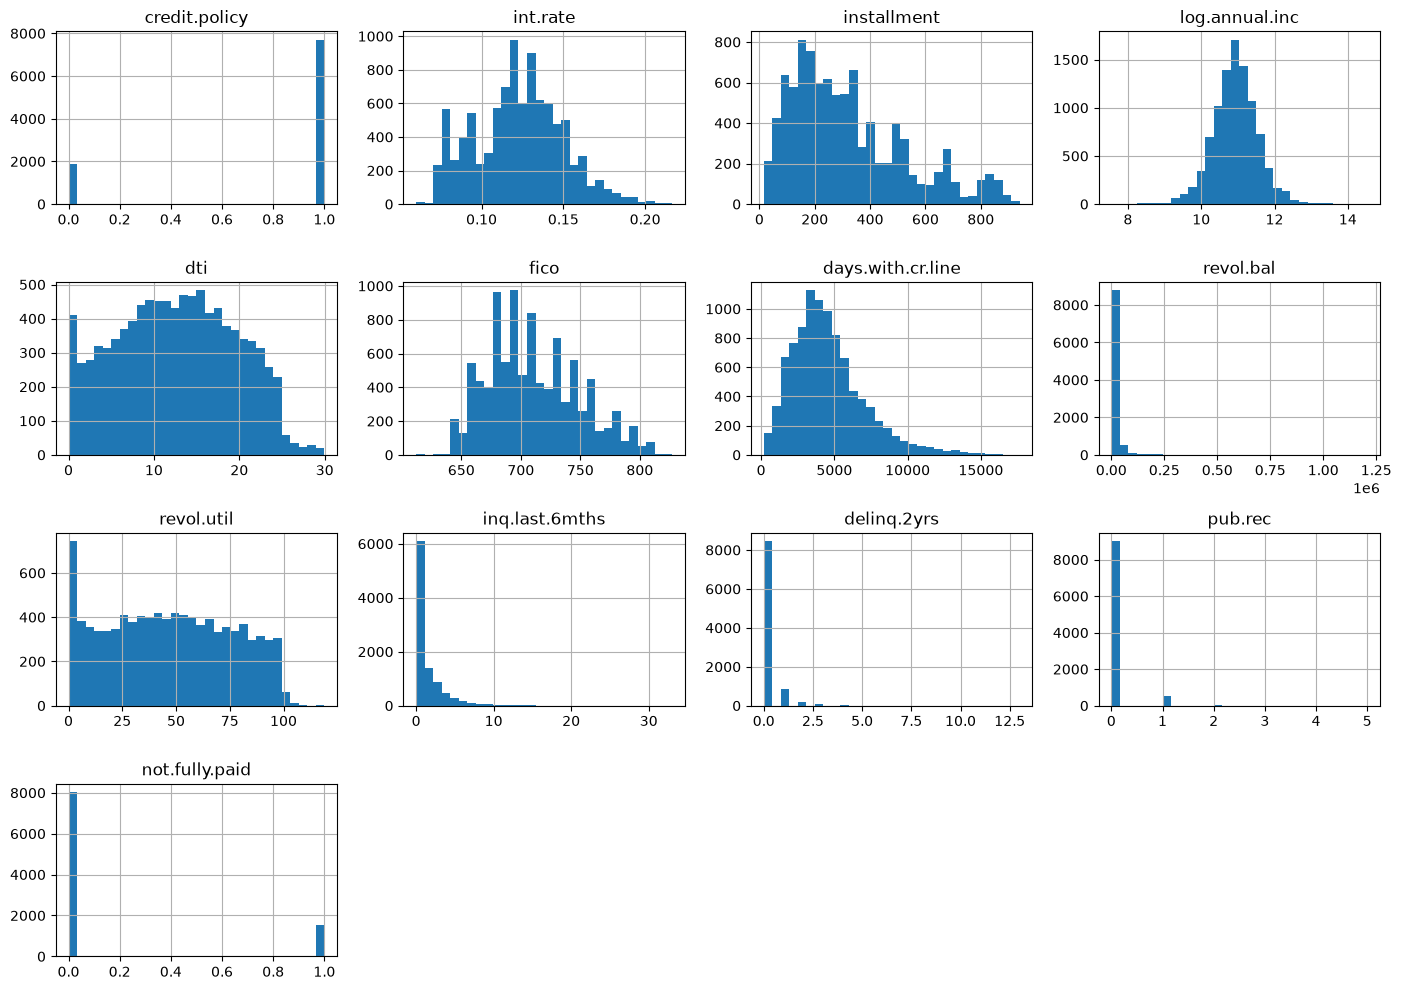

In [3]:
print(loan_data.shape)
print(loan_data.info())
display(loan_data.describe())

matriz_correlacion = loan_data.corr(numeric_only=True)
display(matriz_correlacion.style.background_gradient())

loan_data.hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()

columnas_a_eliminar = [
    "credit.policy",
    'delinq.2yrs',
    'log.annual.inc', 
    'days.with.cr.line', 
    'dti',
]

loan_data = loan_data.drop(columnas_a_eliminar, axis=1)

#### DIVIDIR LOS DATOS

In [4]:
# Queremos que la proporción de prestamos que se pagan y de los que no sea similar, para asegurarlo, estratificamos por ese campo
train_set, test_set = train_test_split(loan_data, train_size=0.85, stratify=loan_data["not.fully.paid"], random_state=42)

#### PREPARAR LOS DATOS

In [5]:
numeric_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
)

categoric_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
)

preprocessing = ColumnTransformer([
    ("numeric", numeric_pipeline, ["int.rate", "installment", "fico", "revol.bal", "revol.util", "inq.last.6mths", "pub.rec"]),
    ("categories", categoric_pipeline, ["purpose"]),
])

y_train = train_set["not.fully.paid"]
X_train = train_set.drop(columns="not.fully.paid")

y_test = test_set["not.fully.paid"]
X_test = test_set.drop(columns="not.fully.paid")

### ENTRENAMIENTO Y EVALUACIÓN DEL MODELO

Usa evaluación cruzada con los siguientes algoritmos:
- Regresión logisitca
- SGDClassifier
- K vecinos mas cercanos
- Random Forest

 y evalua los resultados en el conjunto de entrenamiento con las siguientes métricas: exactitud, prescisión, sensibilidad, f1, curva de roc y área bajo la curva de roc

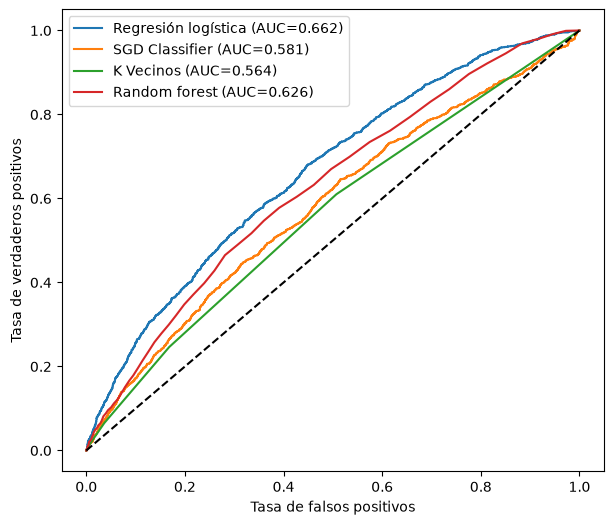

,exactitud,precisión,sensibilidad,f1,auc
Regresión logística,0.8404,0.5357,0.0230,0.0442,0.6624
SGD Classifier,0.8398,0.4000,0.0015,0.0031,0.5809
K Vecinos,0.8198,0.2545,0.0652,0.1038,0.5637
Random forest,0.8354,0.3391,0.0299,0.0550,0.6263


In [6]:
# Modelos a comparar: cada uno es un pipeline (preprocesado + clasificador)
pipeline_regresion_logistica = make_pipeline(preprocessing, LogisticRegression(max_iter=1000))
pipeline_sgd = make_pipeline(preprocessing, SGDClassifier(random_state=42))
pipeline_knn = make_pipeline(preprocessing, KNeighborsClassifier())
pipeline_random_forest = make_pipeline(preprocessing, RandomForestClassifier(random_state=42))


def evaluar_modelo(nombre_modelo, pipeline, X_train, y_train):
    # Clases predichas: para exactitud, precisión, sensibilidad y F1
    clases_predichas = cross_val_predict(pipeline, X_train, y_train, cv=3)

    # Puntuaciones: para la curva ROC y el AUC (Area Under Curve)
    # (SGD no tiene predict_proba, así que se usa decision_function)
    if hasattr(pipeline, "predict_proba"):
        puntuaciones = cross_val_predict(
            pipeline, X_train, y_train, cv=3, method="predict_proba"
        )[:, 1]
    else:
        puntuaciones = cross_val_predict(
            pipeline, X_train, y_train, cv=3, method="decision_function"
        )

    tasa_falsos_positivos, tasa_verdaderos_positivos, _ = roc_curve(y_train, puntuaciones)
    area_bajo_curva_roc = auc(tasa_falsos_positivos, tasa_verdaderos_positivos)
    plt.plot(
        tasa_falsos_positivos,
        tasa_verdaderos_positivos,
        label=f"{nombre_modelo} (AUC={area_bajo_curva_roc:.3f})",
    )

    return {
        "exactitud": accuracy_score(y_train, clases_predichas),
        "precisión": precision_score(y_train, clases_predichas, zero_division=0),
        "sensibilidad": recall_score(y_train, clases_predichas),
        "f1": f1_score(y_train, clases_predichas),
        "auc": area_bajo_curva_roc,
    }

plt.figure(figsize=(7, 6))

metricas_por_modelo = {
    "Regresión logística": evaluar_modelo("Regresión logística", pipeline_regresion_logistica, X_train, y_train),
    "SGD Classifier": evaluar_modelo("SGD Classifier", pipeline_sgd, X_train, y_train),
    "K Vecinos": evaluar_modelo("K Vecinos", pipeline_knn, X_train, y_train),
    "Random forest": evaluar_modelo("Random forest", pipeline_random_forest, X_train, y_train),
}

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend()
plt.show()

pd.DataFrame(metricas_por_modelo).T.round(4)


# Apuntes:
# 	                |   El modelo dice “impago”	            |    El modelo dice “pagado”
# ------------------|---------------------------------------|--------------------------------------------------
# Realmente impago  |   Verdadero positivo (VP): acierto	|    Falso negativo (FN): impago que se le escapó
# Realmente pagado	|   Falso positivo (FP): falsa alarma	|    Verdadero negativo (VN): acierto

# Exactitud: de todos los préstamos, qué proporción acierta.
# (VP + VN) / total
# Es la más intuitiva y la más engañosa aquí. Un modelo que dijera siempre “pagado” acertaría 84 de 100 (84 %) sin detectar ningún impago.

# Precisión: cuando el modelo dice “impago”, qué proporción de veces tiene razón.
# VP / (VP + FP)
# Mide la fiabilidad de las alarmas. Si es baja, el modelo marca como impagos muchos préstamos que en realidad se pagan.

# Sensibilidad (recall): de los impagos reales, qué proporción detecta.
# VP / (VP + FN)
# Mide cuántos impagos se le escapan. Si es 0,10, el modelo solo ve 1 de cada 10. En este problema suele ser la más importante, 
# porque un impago no detectado es dinero perdido. El modelo que siempre dice “pagado” tiene sensibilidad 0.

# F1: una sola nota que combina precisión y sensibilidad (su media armónica).
# 2 · precisión · sensibilidad / (precisión + sensibilidad)
# Hace falta porque las dos se compensan: si el modelo marca todo como impago, la sensibilidad es 1 pero la precisión es mínima. 
# La media armónica solo sale alta si ambas lo son, así que un valor bajo en una de las dos arrastra el F1.

### OPMITZACIÓN DEL MODELO

#### OPTIMIZACIÓN

Usa búsqueda exhaustiva o búsqueda aleatoria para optimizar el mejor modelo del apartado anterior

In [7]:
from scipy.stats import loguniform

parametros_grid_search = {
    "logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "logisticregression__solver": ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga']
}

parametros_randomized_search = {
    "logisticregression__C": loguniform(1e-3, 1e2),
    "logisticregression__solver": ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga']
}

grid_search = GridSearchCV(
    estimator=pipeline_regresion_logistica, 
    param_grid=parametros_grid_search,
    cv=3,
    scoring="roc_auc"
)
grid_search.fit(X_train, y_train)

randomized_search = RandomizedSearchCV(
    estimator=pipeline_regresion_logistica,
    param_distributions=parametros_randomized_search,
    cv=3,
    scoring="roc_auc",
    random_state=42,
)
randomized_search.fit(X_train, y_train)


print(grid_search.best_params_)
print(randomized_search.best_params_)

/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


{'logisticregression__C': 0.1, 'logisticregression__solver': 'liblinear'}
{'logisticregression__C': np.float64(0.0745934328572655), 'logisticregression__solver': 'sag'}


#### EVALUACIÓN EN EL CONJUNTO DE PRUEBA

Evalúa el conjunto de pruebas con diferentes métricas

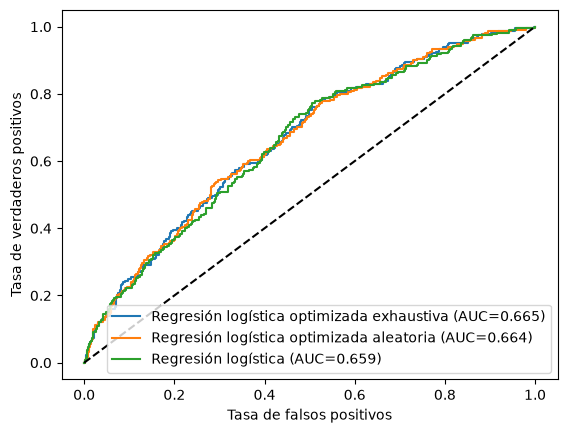

,exactitud,precisión,sensibilidad,f1,auc
Regresión logística optimizada exhaustiva,0.8386,0.4375,0.0304,0.0569,0.6647
Regresión logística optimizada aleatoria,0.8379,0.4000,0.0261,0.0490,0.6640
Regresión logística,0.8392,0.4762,0.0435,0.0797,0.6591


In [8]:
metricas_por_modelo = {
    "Regresión logística optimizada exhaustiva": evaluar_modelo("Regresión logística optimizada exhaustiva", grid_search.best_estimator_, X_test, y_test),
    "Regresión logística optimizada aleatoria": evaluar_modelo("Regresión logística optimizada aleatoria", randomized_search.best_estimator_, X_test, y_test),
    "Regresión logística": evaluar_modelo("Regresión logística", pipeline_regresion_logistica, X_test, y_test),
}

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend()
plt.show()

pd.DataFrame(metricas_por_modelo).T.round(4)

### PRESENTACIÓN DE LA SOLUCIÓN

Guarda mejor modelo (pipeline de preparación de los datos + modelo) y  haz un script de python que te pida los datos necesarios ('int_rate', 'installment', 'fico',  'revol_bal', 'revol_util', 'inq_last_6mths', 'pub_rec' y 'purpose') y prediga la solución.

In [9]:
import os

if not os.path.exists('./Resultados'):
    os.makedirs('./Resultados')

modelo_final = randomized_search.best_estimator_

joblib.dump(modelo_final, "Resultados/modelo_final_prestamos.joblib")

['Resultados/modelo_final_prestamos.joblib']

## EJERCICIO 2

Vamos a trabajar conun conjunto de datos digits.

Crea un clasificador que nos diga de que número se trata.

### RECOPILACIÓN Y PREPARACIÓN DE LOS DATOS

#### OBTENER LOS DATOS

In [10]:
# Cargar el conjunto de datos
digits = load_digits()
X_digits = digits.data
y_digits = digits.target

#### EXPLORAR LOS DATOS

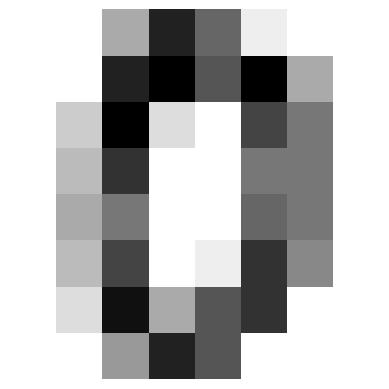

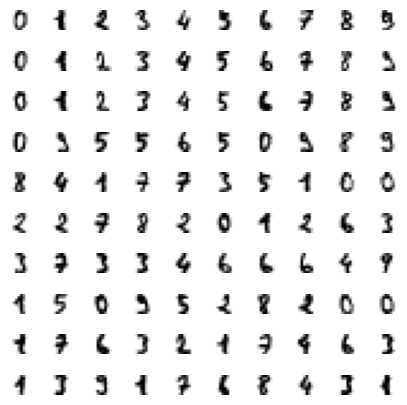

[0 1 2 ... 8 9 8]


3    183
1    182
5    182
4    181
6    181
9    180
7    179
0    178
2    177
8    174
Name: count, dtype: int64

In [11]:
# Explorar los datos
def plot_digit(image_data):
    image = image_data.reshape(8, 8)
    plt.imshow(image, cmap="binary")
    plt.axis("off")

some_digit = X_digits[0]
plot_digit(some_digit)
plt.show()

plt.figure(figsize=(5,5))
for idx, image_data in enumerate(X_digits[:100]):
    plt.subplot(10, 10, idx + 1)
    plot_digit(image_data)
plt.subplots_adjust(wspace=1, hspace=1)
plt.show()

print(y_digits)
pd.Series(y_digits).value_counts()

#### DIVIDIR LOS DATOS

1


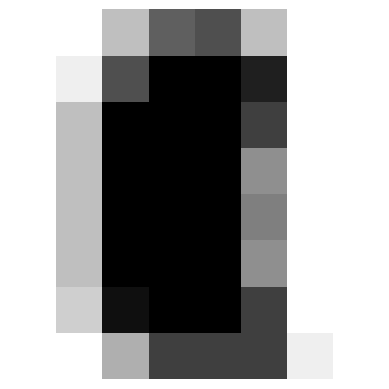

In [12]:
# Dividir los datos

X_digits_train, X_digits_test, y_digits_train, y_digits_test = train_test_split(X_digits, y_digits, train_size=0.85, random_state=42)
plot_digit(X_digits_train[0])
print(y_digits_train[0])

#### PREPARAR LOS DATOS

In [13]:
preprocessing_digits = StandardScaler()

### ENTRENAMIENTO Y EVALUACIÓN DEL MODELO

Usa evaluación cruzada con los siguientes algoritmos, evalua los resultados en el conjunto de entrenamiento (exactitud) y calcula la matriz de confusión:
- Regresión logistica
- Maquinas de vectores de sorpote
- Random forest

In [14]:
lr_digits = make_pipeline(preprocessing_digits, LogisticRegression(random_state=42))
lr_digits.fit(X_digits_train, y_digits_train)
lr_digits_predicciones = cross_val_predict(lr_digits, X_digits_train, y_digits_train)
matriz_confusion_lr_digits = confusion_matrix(y_digits_train, lr_digits_predicciones)
lr_accuracy = accuracy_score(y_digits_train, lr_digits_predicciones)
print("LogisticRegression")
print(f"Precisión: {lr_accuracy}")
print(matriz_confusion_lr_digits)

LogisticRegression
Precisión: 0.9666011787819253
[[154   0   0   0   0   1   0   0   0   0]
 [  0 154   1   2   0   1   1   0   4   1]
 [  0   1 150   0   0   0   0   0   0   0]
 [  0   0   1 153   0   0   0   2   2   1]
 [  0   1   0   0 140   0   0   1   1   1]
 [  0   1   0   0   1 143   1   0   0   3]
 [  0   1   0   0   1   0 148   0   1   0]
 [  0   0   0   0   1   0   0 151   1   0]
 [  0   9   1   1   0   1   0   0 143   0]
 [  0   2   0   0   0   2   0   1   1 140]]


In [15]:
svc_digits = make_pipeline(preprocessing_digits, SVC(random_state=42))
svc_digits.fit(X_digits_train, y_digits_train)
svc_digits_predicciones = cross_val_predict(svc_digits, X_digits_train, y_digits_train)
matriz_confusion_svc_digits = confusion_matrix(y_digits_train, svc_digits_predicciones)
svc_accuracy = accuracy_score(y_digits_train, svc_digits_predicciones)
print("\nVectores de Soporte")
print(f"Precisión: {svc_accuracy}")
print(matriz_confusion_svc_digits)


Vectores de Soporte
Precisión: 0.9803536345776032
[[155   0   0   0   0   0   0   0   0   0]
 [  0 163   0   0   1   0   0   0   0   0]
 [  0   0 147   0   3   0   0   1   0   0]
 [  0   0   0 154   1   0   0   1   3   0]
 [  0   0   0   0 140   0   0   2   1   1]
 [  0   0   0   1   1 146   0   0   0   1]
 [  0   0   0   0   0   0 151   0   0   0]
 [  0   0   0   0   1   0   0 152   0   0]
 [  0   3   1   1   1   0   0   0 149   0]
 [  0   0   0   0   0   2   1   1   2 140]]


In [16]:
rf_digits = make_pipeline(preprocessing_digits, RandomForestClassifier(random_state=42))
rf_digits.fit(X_digits_train, y_digits_train)
rf_digits_predicciones = cross_val_predict(rf_digits, X_digits_train, y_digits_train)
matriz_confusion_rf_digits = confusion_matrix(y_digits_train, rf_digits_predicciones)
rf_accuracy = accuracy_score(y_digits_train, rf_digits_predicciones)
print("\nRandom Forest")
print(f"Precisión: {rf_accuracy}")
print(matriz_confusion_rf_digits)


Random Forest
Precisión: 0.9751146037982973
[[154   0   0   0   1   0   0   0   0   0]
 [  0 164   0   0   0   0   0   0   0   0]
 [  1   0 149   0   0   0   0   0   1   0]
 [  0   0   0 151   0   0   0   2   4   2]
 [  0   0   0   0 141   0   0   2   0   1]
 [  0   0   0   1   1 144   1   0   1   1]
 [  1   0   0   0   0   0 149   0   1   0]
 [  0   0   0   0   1   0   0 151   1   0]
 [  0   6   1   0   1   0   0   0 146   1]
 [  0   0   0   2   0   2   0   0   2 140]]


In [17]:
pd.DataFrame({
    "LogisticRegression": {"Exactitud": lr_accuracy},
    "SVC": {"Exactitud": svc_accuracy},
    "RandomForest": {"Exactitud": rf_accuracy},
}).T.sort_values("Exactitud", ascending=False)

,Exactitud
SVC,0.980354
RandomForest,0.975115
LogisticRegression,0.966601


### OPTIMIZACIÓN DEL MODELO

#### OPTIMIZACIÓN

Usa búsqueda exhaustiva o búsqueda aleatoria para optimizar el mejor modelo del apartado anterior

In [ ]:
grid_search_digits = GridSearchCV(lr_digits)

#### EVALUACIÓN EN EL CONJUNTO DE PRUEBA

### PRESENTACIÓN DE LA SOLUCIÓN

Simplemente guarda el modelo